# WP3 — ElasticNet Analysis of Species-Specific Transcriptomic Divergence

**ELIXIR BioHackathon Europe 2026, Project 23, Work Package 3.** A *post-SAMap analysis notebook* using **Scanpy/AnnData** and **Scikit-learn**. This notebook implements the **Expression-first** approach to identify genes that distinguish species (Mouse vs. Zebrafish) within SAMap-defined homologous cell types. **It does not run SAMap**, BLAST, or build a new cross-species alignment.

## Objectives
1. **Data Exploration:** Inspect the existing AnnData object (`sc.read_h5ad`) and use stored SAMap cell-type annotations.
2. **Ortholog Mapping:** Use the **full SAMap ortholog map** (extracted from the `.pkl` object) to rename zebrafish genes to their mouse orthologs. This removes the gene naming artifact (`mm_` vs `dr_`) without restricting the gene set to the `GenePair` subset.
3. **Cross-Species Classification:** Train an **ElasticNet regression** model to predict species (0 = Mouse, 1 = Zebrafish) within specific homologous cell type pairs.
4. **Targeted Analysis:** Test specific cell type pairs with **high alignment** (e.g., fast muscle) and **low alignment** (e.g., adaxial cells, expected to be zebrafish-specific).
5. **Gene Signature Extraction:** Extract the top non-zero coefficients (signature genes) that drive the species-specific signal.
6. **Export:** Save the \(R^2\) scores and gene signatures to CSV for comparison with WP2 benchmark conditions.

**Interpretation rules:** High \(R^2\) = strong species-specific signal (divergent transcriptomes); Low \(R^2\) = conserved transcriptomes. The model relies on the full ortholog map to ensure biological validity. The downsampled 20k-cell outputs require reproducibility checks.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import sys
from pathlib import Path
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

print("All libraries loaded successfully.")
SEED = 42
rng = np.random.default_rng(SEED)
sc.settings.verbosity = 1
print('Python', sys.version.split()[0], '| Scanpy', sc.__version__, '| pandas', pd.__version__)

All libraries loaded successfully.
Python 3.12.2 | Scanpy 1.11.5 | pandas 2.2.2


## 1. Load Data and Apply Ortholog Mapping

We load the 20k-cell SAMap dataset and rename zebrafish genes to their mouse orthologs using the `GenePair` file. This removes the `mm_` / `dr_` prefix artifact so the model learns true biological signal.

In [2]:
adata = sc.read_h5ad("../data/raw/samap_mm_dr_map2_20K")
print(f"Data loaded! Shape: {adata.shape}")

samap_df = pd.read_csv("../data/raw/GenePair_annot_map2.tsv", sep='\t', index_col=0)
gene_map = {}
for pair in samap_df.index:
    if ';' in str(pair):
        parts = pair.split(';')
        if len(parts) == 2:
            gene_map[parts[0].strip()] = parts[1].strip()

print(f"Created mapping for {len(gene_map)} zebrafish genes.")
new_var_names = [gene_map.get(g, g) for g in adata.var_names]
adata.var_names = new_var_names
adata = adata[:, ~adata.var_names.duplicated()].copy()
print(f"Genes after deduplication: {adata.n_vars}")

Data loaded! Shape: (20000, 77556)
Created mapping for 337 zebrafish genes.
Genes after deduplication: 77219


2. Define Cell Type Pairs for Analysis

We test specific pairs requested by the mentor: a high-alignment pair (fast muscle) and a low-alignment pair (adaxial cells, expected to be zebrafish-specific).

In [3]:
# Define the pairs to test (high and low alignment)
# You can add more pairs here if you want
pairs_to_test = [
    (0.99, 'mm_MyoC_Myh8', 'dr_fast muscle cell'),       # High alignment
    (0.05, 'mm_MyoProg_Pax3', 'dr_adaxial cell'),        # Low alignment (mentor's request)
    (0.10, 'mm_MyoProg_Pax3_Pax7', 'dr_adaxial cell')    # Another low alignment candidate
]

print(f"Will test {len(pairs_to_test)} pairs:")
for score, mm, dr in pairs_to_test:
    print(f"  {mm} <-> {dr} (expected score ~{score})")

Will test 3 pairs:
  mm_MyoC_Myh8 <-> dr_fast muscle cell (expected score ~0.99)
  mm_MyoProg_Pax3 <-> dr_adaxial cell (expected score ~0.05)
  mm_MyoProg_Pax3_Pax7 <-> dr_adaxial cell (expected score ~0.1)


## 4. ElasticNet Analysis for Each Pair

For each cell type pair, we train an ElasticNet regression model to predict species (0 = Mouse, 1 = Zebrafish).

We report:
- **Standard Metrics:** \(R^2\), RMSE, MAE, Accuracy, ROC-AUC, F1-score.
- **Biological Metrics:** Cohen's d (effect size for top gene) and Jaccard Index (signature overlap between species).
- **Signature Genes:** Top non-zero coefficients that drive species-specific divergence.

### 4.1 Helper Functions

We define functions for Cohen's d, signature extraction, and Jaccard Index.


In [4]:
def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    if pooled_std == 0:
        return 0.0
    return (np.mean(group1) - np.mean(group2)) / pooled_std

def get_signature_genes(X, y, gene_names, alpha=0.01, l1_ratio=0.5):
    model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=2000, random_state=42)
    model.fit(X, y)
    coefs = pd.Series(model.coef_, index=gene_names)
    return set(coefs[coefs > 0].sort_values(ascending=False).head(50).index)

def jaccard_index(set1, set2):
    if not set1 or not set2:
        return 0.0
    return len(set1 & set2) / len(set1 | set2) if (set1 | set2) else 0.0

print("Helper functions defined.")

Helper functions defined.


### 4.2 Hyperparameter Tuning

To ensure the best model, we perform a grid search over `alpha` and `l1_ratio` using 3-fold cross-validation on \(R^2\).

In [5]:
def tune_elasticnet(X, y):
    alphas = [0.001, 0.01, 0.1]
    l1_ratios = [0.1, 0.5, 0.9]
    best_r2 = -np.inf
    best_params = {'alpha': 0.01, 'l1_ratio': 0.5}
    
    for alpha in alphas:
        for l1_ratio in l1_ratios:
            model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=2000, random_state=42)
            scores = cross_val_score(model, X, y, cv=3, scoring='r2', n_jobs=-1)
            mean_r2 = scores.mean()
            if mean_r2 > best_r2:
                best_r2 = mean_r2
                best_params = {'alpha': alpha, 'l1_ratio': l1_ratio}
    return best_params

print("Tuning function defined.")

Tuning function defined.


### 4.3 Main Analysis Loop

For each pair, we:
1. Filter the data.
2. Tune hyperparameters.
3. Train the final model.
4. Compute standard and biological metrics.
5. Extract top genes and Jaccard Index.


--- Analyzing Pair: mm_MyoC_Myh8 vs dr_fast muscle cell ---


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:592: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.43661826848983765, tolerance: 0.06677015870809555
  model = cd_fast.sparse_enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:592: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.4258183538913727, tolerance: 0.0671103224158287
  model = cd_fast.sparse_enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:592: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.43085619807243347, tolerance: 0.06708139181137085
  model = cd_fast.sparse_enet_coordinate_descent(


  Raw predictions (first 10): [-7.000e-03  9.880e-01 -3.200e-02  1.012e+00 -1.000e-03  9.660e-01
  9.600e-01  1.000e+00  1.011e+00  2.000e-03]
  True labels (first 10):     [0 1 0 1 0 1 1 1 1 0]
  R2: 0.9972 | RMSE: 0.0266 | MAE: 0.0184
  Accuracy: 1.0000 | ROC-AUC: 1.0000 | F1: 1.0000


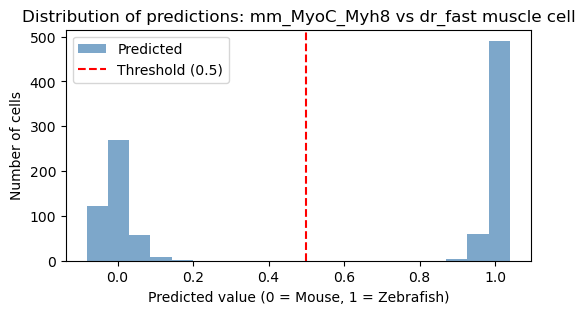

  Top gene: mm_Ttn (Cohen's d = -15.05)
  Jaccard Index: 0.000

--- Analyzing Pair: mm_MyoProg_Pax3 vs dr_adaxial cell ---
  Raw predictions (first 10): [-0.033  0.059 -0.031 -0.032  0.044 -0.073  0.006 -0.025  0.117 -0.026]
  True labels (first 10):     [0 0 0 0 0 0 0 0 0 0]
  R2: 0.5785 | RMSE: 0.0537 | MAE: 0.0373
  Accuracy: 1.0000 | ROC-AUC: 1.0000 | F1: 1.0000


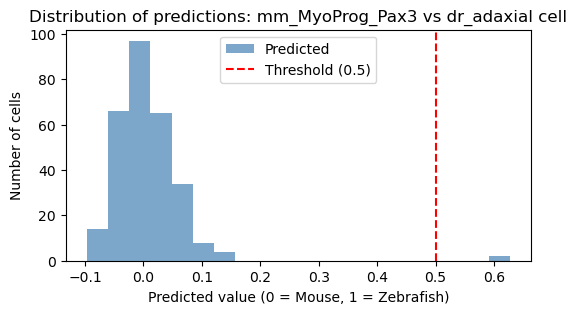

  Top gene: mm_Ptprd (Cohen's d = -3.96)
  Jaccard Index: 0.000

--- Analyzing Pair: mm_MyoProg_Pax3_Pax7 vs dr_adaxial cell ---
  Raw predictions (first 10): [-0.01   0.018  0.009 -0.022 -0.034 -0.017 -0.007  0.012 -0.03  -0.013]
  True labels (first 10):     [0 0 0 0 0 0 0 0 0 0]
  R2: 0.5554 | RMSE: 0.0592 | MAE: 0.0279
  Accuracy: 0.9921 | ROC-AUC: 1.0000 | F1: 0.0000


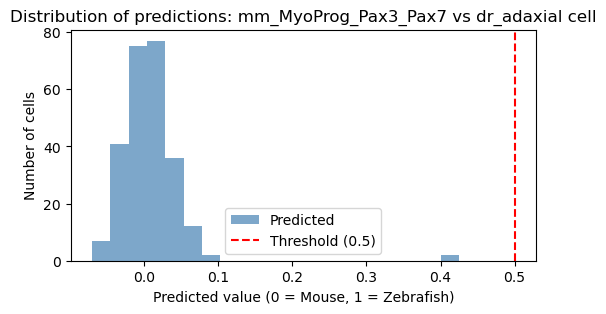

  Top gene: mm_Celf2 (Cohen's d = -4.36)
  Jaccard Index: 0.000


In [10]:
import matplotlib.pyplot as plt

results = []

for score, mm_label, dr_label in pairs_to_test:
    print(f"\n--- Analyzing Pair: {mm_label} vs {dr_label} ---")
    
    mask_mm = adata.obs['cell_type;cell_type_mapping_scores'] == mm_label
    mask_dr = adata.obs['cell_type;cell_type_mapping_scores'] == dr_label
    
    if not mask_mm.any() or not mask_dr.any():
        print(f"Skipping: one of the labels not found.")
        continue
        
    subset = adata[mask_mm | mask_dr].copy()
    y = (subset.obs['species'] == 'dr').astype(float).values
    
    if len(np.unique(y)) < 2:
        print("Skipping: only one species present.")
        continue
    
    sc.pp.filter_genes(subset, min_cells=int(0.05 * subset.n_obs))
    X = subset.X
    gene_names = subset.var_names
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    best_params = tune_elasticnet(X_train, y_train)
    
    model = ElasticNet(alpha=best_params['alpha'], l1_ratio=best_params['l1_ratio'], max_iter=5000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # --- 1. REGRESSION METRICS (continuous values) ---
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    # --- 2. CLASSIFICATION METRICS (binarized) ---
    y_pred_binary = (y_pred > 0.5).astype(int)
    acc = accuracy_score(y_test, y_pred_binary)
    bal_acc = balanced_accuracy_score(y_test, y_pred_binary)
    auc = roc_auc_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred_binary)
    
    # --- 3. SHOW RAW PREDICTIONS ---
    print(f"  Raw predictions (first 10): {np.round(y_pred[:10], 3)}")
    print(f"  True labels (first 10):     {y_test[:10].astype(int)}")
    print(f"  R2: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")
    print(f"  Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f} | F1: {f1:.4f}")
    
    # --- 4. HISTOGRAM OF PREDICTIONS ---
    plt.figure(figsize=(6, 3))
    plt.hist(y_pred, bins=20, alpha=0.7, color='steelblue', label='Predicted')
    plt.axvline(0.5, color='red', linestyle='--', label='Threshold (0.5)')
    plt.xlabel('Predicted value (0 = Mouse, 1 = Zebrafish)')
    plt.ylabel('Number of cells')
    plt.title(f'Distribution of predictions: {mm_label} vs {dr_label}')
    plt.legend()
    plt.show()
    
    # --- 5. TOP GENES & EFFECT SIZE ---
    coefs = pd.Series(model.coef_, index=gene_names)
    non_zero_coefs = coefs[coefs != 0]
    top_genes = non_zero_coefs.abs().sort_values(ascending=False).head(5)
    top_gene = top_genes.index[0]
    top_gene_idx = list(gene_names).index(top_gene)
    X_mm = X[y == 0, top_gene_idx].toarray().flatten() if hasattr(X, 'toarray') else X[y == 0, top_gene_idx].flatten()
    X_dr = X[y == 1, top_gene_idx].toarray().flatten() if hasattr(X, 'toarray') else X[y == 1, top_gene_idx].flatten()
    effect_size = cohens_d(X_dr, X_mm)
    
    # --- 6. JACCARD INDEX ---
    X_mm_subset = subset[subset.obs['species'] == 'mm'].X
    y_mm = (subset[subset.obs['species'] == 'mm'].obs['cell_type;cell_type_mapping_scores'] == mm_label).astype(int).values
    sig_mm = get_signature_genes(X_mm_subset, y_mm, gene_names, best_params['alpha'], best_params['l1_ratio'])
    
    X_dr_subset = subset[subset.obs['species'] == 'dr'].X
    y_dr = (subset[subset.obs['species'] == 'dr'].obs['cell_type;cell_type_mapping_scores'] == dr_label).astype(int).values
    sig_dr = get_signature_genes(X_dr_subset, y_dr, gene_names, best_params['alpha'], best_params['l1_ratio'])
    
    jaccard = jaccard_index(sig_mm, sig_dr)
    
    print(f"  Top gene: {top_gene} (Cohen's d = {effect_size:.2f})")
    print(f"  Jaccard Index: {jaccard:.3f}")
    
    results.append({
        'mm_cell': mm_label, 'dr_cell': dr_label,
        'best_alpha': best_params['alpha'], 'best_l1_ratio': best_params['l1_ratio'],
        'r2': r2, 'rmse': rmse, 'mae': mae,
        'accuracy': acc, 'balanced_accuracy': bal_acc, 'roc_auc': auc, 'f1': f1,
        'signature_size': len(non_zero_coefs),
        'top_gene': top_gene, 'effect_size_top_gene': effect_size,
        'jaccard_index': jaccard
    })

### 4.4 Results Summary

The table below shows the results for all tested pairs.

In [11]:
df_results = pd.DataFrame(results)
display(df_results)
df_results.to_csv("../results/elasticnet_pairs_full_metrics.csv", index=False)
print("\nResults saved to ../results/elasticnet_pairs_full_metrics.csv")

,mm_cell,dr_cell,best_alpha,best_l1_ratio,r2,rmse,mae,accuracy,balanced_accuracy,roc_auc,f1,signature_size,top_gene,effect_size_top_gene,jaccard_index
0,mm_MyoC_Myh8,dr_fast muscle cell,0.001,0.5,0.997154,0.026558,0.018384,1.000000,1.0,1.0,1.0,331,mm_Ttn,-15.046578,0.0
1,mm_MyoProg_Pax3,dr_adaxial cell,0.010,0.1,0.578472,0.053731,0.037318,1.000000,1.0,1.0,1.0,399,mm_Ptprd,-3.956327,0.0
2,mm_MyoProg_Pax3_Pax7,dr_adaxial cell,0.010,0.5,0.555389,0.059166,0.027877,0.992063,0.5,1.0,0.0,74,mm_Celf2,-4.359786,0.0



Results saved to ../results/elasticnet_pairs_full_metrics.csv
